# 12 Network models

## Representing and measuring networks

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for sections 12.1-12.2 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

Networks allow us to ask questions about **connections**, not just positions.
The Seven Bridges of Königsberg (textbook Fig. 12.1) is the historical example:
can one cross each bridge exactly once and return to the starting point?
We represent each landmass by a node and each bridge by an edge.

**Historical context:** Euler (1736), *Solutio problematis ad geometriam situs
pertinentis*, introduced the reasoning behind the bridges problem. For a broad
modern introduction, see Newman (2003), [*The structure and function of complex
networks*](https://doi.org/10.1137/S003614450342480), *SIAM Review* **45**, 167–256.

### The Seven Bridges of Königsberg

Check the map of Könisberg: multiple bridges can connect the same two landmasses. 

Thus we represent the map as a **multigraph**: the landmasses are the nodes and the bridges are the links.

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

from pathlib import Path
import sys
sys.path.insert(0, "../12_modules")

import nm_visualize as vis

In [2]:
bridges = nx.MultiGraph()
bridges.add_edges_from([
    ("A", "C"), ("A", "C"), ("B", "C"), ("B", "C"),
    ("C", "D"), ("A", "D"), ("B", "D")
])
print("Number of bridges:", bridges.number_of_edges())
print("Landmass degrees:", dict(bridges.degree()))

Number of bridges: 7
Landmass degrees: {'A': 3, 'C': 5, 'B': 3, 'D': 3}


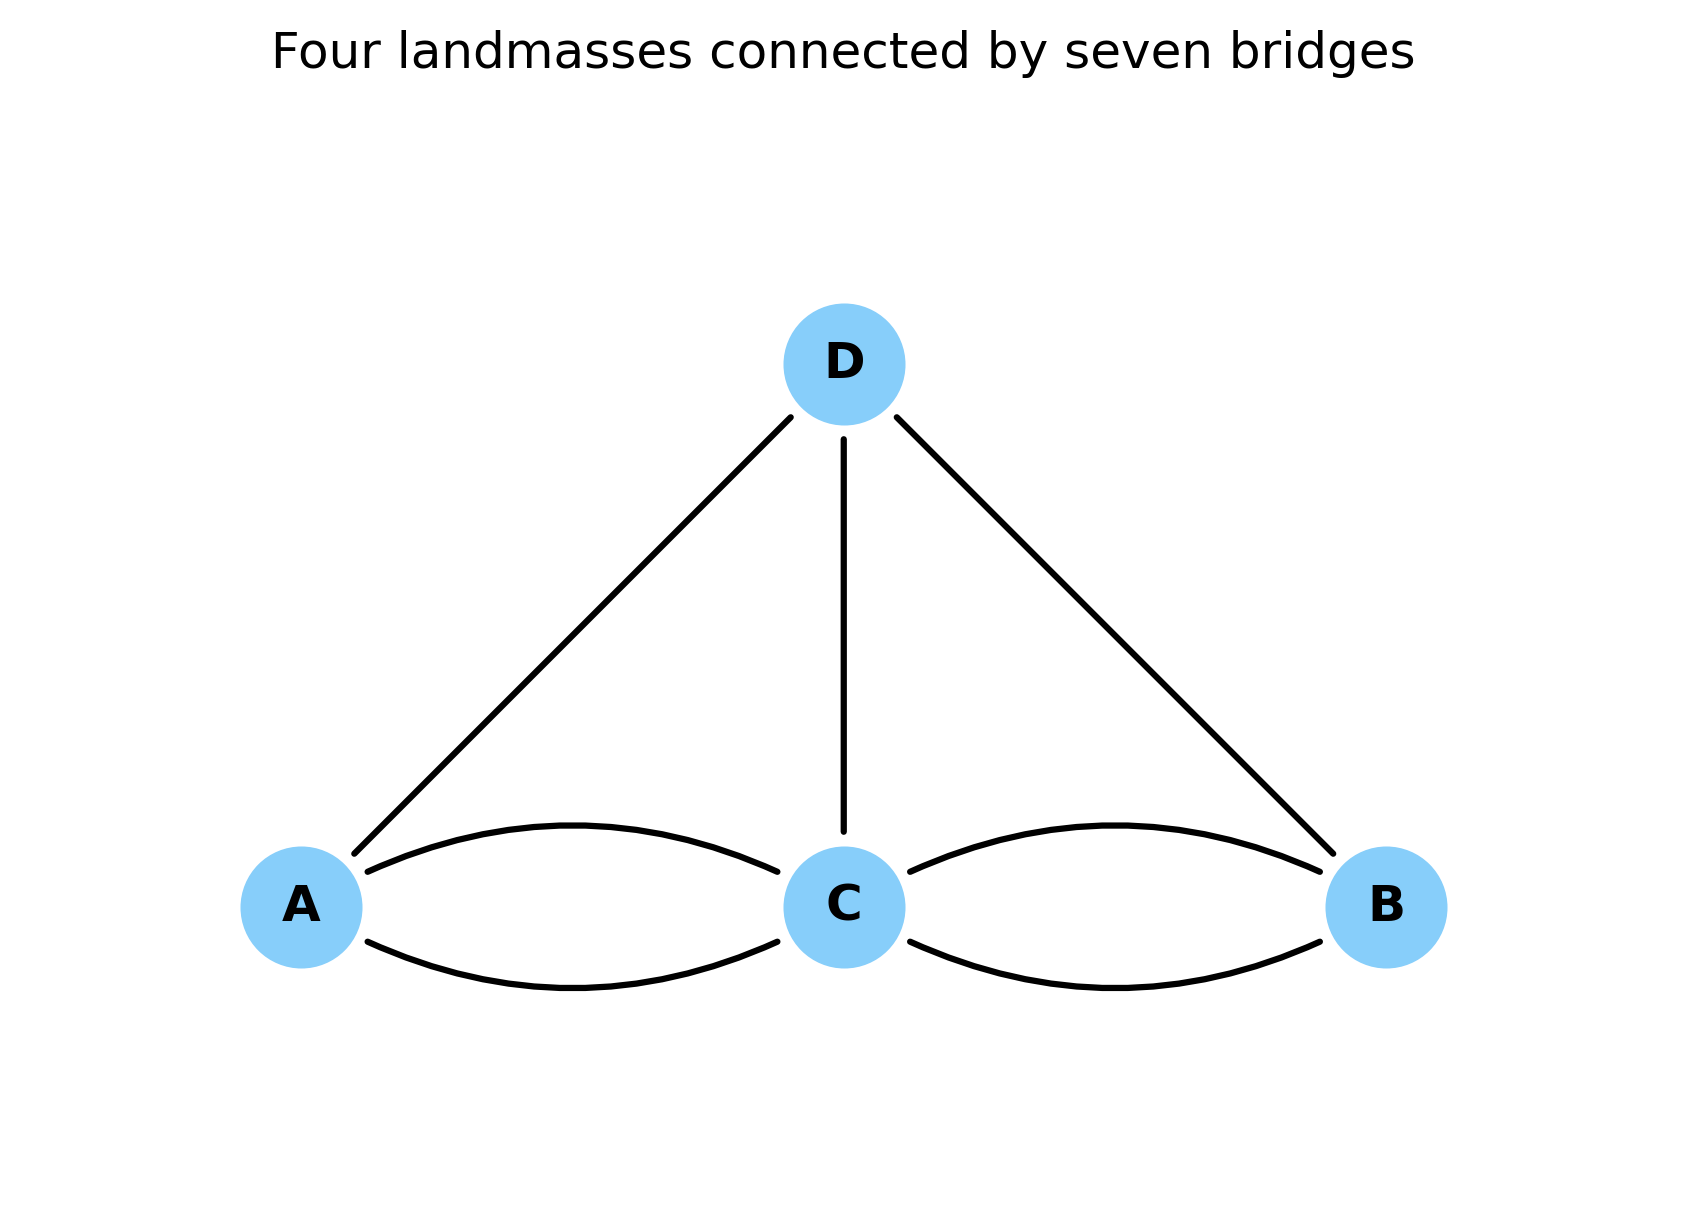

In [3]:
bridge_positions = {
    "A": (-1, 0), 
    "B": (1, 0),
    "C": (0, 0), 
    "D": (0, 1)
}

# # the following lines substitute:
# nx.draw_networkx(
#    bridges, bridge_positions, node_color="lightskyblue",
#    node_size=800, font_weight="bold")
# # as it not always works

fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

nx.draw_networkx_nodes(
    bridges, bridge_positions,
    node_color="lightskyblue", node_size=800, ax=ax
)
nx.draw_networkx_labels(
    bridges, bridge_positions,
    font_weight="bold", ax=ax
)

edges = [
    ("A", "C", 0.3),
    ("A", "C", -0.3),
    ("B", "C", 0.3),
    ("B", "C", -0.3),
    ("C", "D", 0.0),
    ("A", "D", 0.0),
    ("B", "D", 0.0)
]

for u, v, curvature in edges:
    arrow = FancyArrowPatch(
        bridge_positions[u],
        bridge_positions[v],
        connectionstyle=f"arc3,rad={curvature}",
        arrowstyle="-",
        linewidth=1.5,
        color="black",
        shrinkA=18,
        shrinkB=18,
        mutation_scale=10
    )
    ax.add_patch(arrow)

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_aspect("equal")
ax.set_title("Four landmasses connected by seven bridges")
ax.axis("off")

plt.show()

## 12.1 The adjacency matrix

Graph types:
- binary/weighted 
- directed/undirected 

Let's consider a simple, binary, undirected graph, with $N$ nodes.

We can describe it through its **adjacency matrix** $A$:

- $N \times N$ matrix
- $A_{ij}$ is either 0 (nodes not connected) or 1 (nodes connected)
- symmetrical: $A_{ij}=A_{ji}$ 
- always $A_{ii}=0$ 

Note that, instead of the *adjacency matrix*, we can use a **list of connected edges** 

Let's see an example:

In [4]:
n = 6
A = np.zeros((n, n), dtype=int)
edges = [(0, 1), (0, 2), (1, 2), (2, 3),
         (3, 4), (3, 5), (4, 5)]
for i, j in edges:
    A[i, j] = 1
    A[j, i] = 1
print(A)

[[0 1 1 0 0 0]
 [1 0 1 0 0 0]
 [1 1 0 1 0 0]
 [0 0 1 0 1 1]
 [0 0 0 1 0 1]
 [0 0 0 1 1 0]]


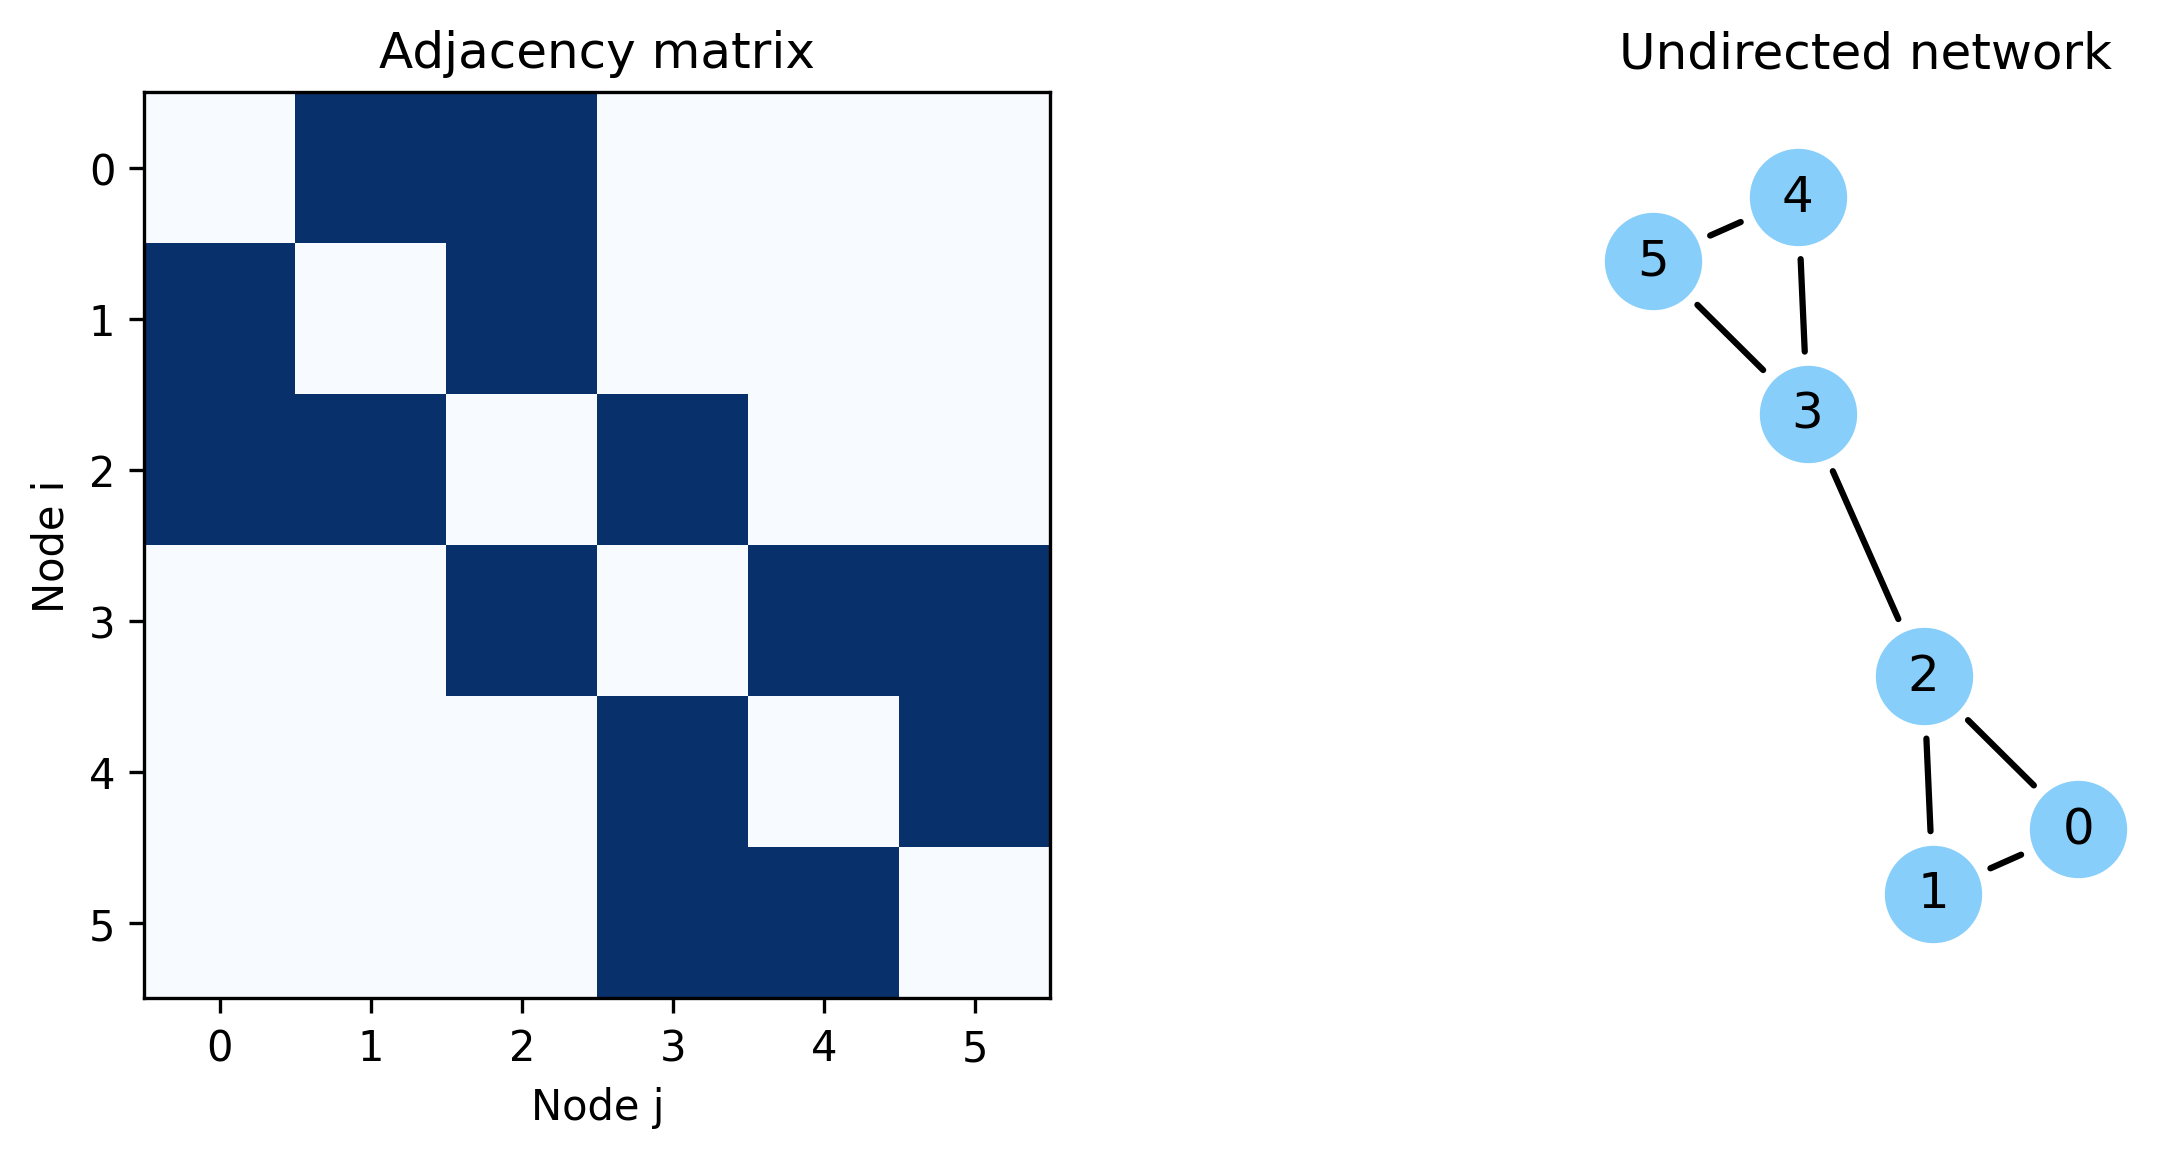

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

axes[0].imshow(A, cmap="Blues", vmin=0, vmax=1)
axes[0].set(
    xlabel="Node j", 
    ylabel="Node i", 
    title="Adjacency matrix"
)

G = nx.from_numpy_array(A)
vis.draw_network_labels(G, ax=axes[1])  

axes[1].set_title("Undirected network")
plt.show()

**Degree** of a node

The degree $k_i$ is the number of neighbors: 

$$k_i=\sum_j A_{ij}$$

In any simple undirected graph, **every edge contributes twice** to the degree sum.

In [6]:
degrees = np.zeros(n, dtype=int)
for i in range(n):
    for j in range(n):
        degrees[i] += A[i, j]
print(f"Degrees: {degrees}")
print(f"Sum of degrees: {degrees.sum()}")

Degrees: [2 2 3 3 2 2]
Sum of degrees: 14


We can get the degree of each nodes also using 
`NumPy` and `NetworkX`

In [7]:
print(f"Degrees (NumPy): {A.sum(axis=1)}")
print(f"NetworkX: {[degree for _, degree in G.degree()]}")

assert np.array_equal(degrees, A.sum(axis=1))

Degrees (NumPy): [2 2 3 3 2 2]
NetworkX: [2, 2, 3, 3, 2, 2]


**Adjacency matrix** to calculate **number of walks between two nodes**.

For simple unweighted graphs:
- $A^t$ counts **walks** of length $t$, which may repeat nodes or edges. 


In [8]:
print("A squared:\n", A @ A)
print("Number of two-step walks 0 to 3:", (A @ A)[0, 3])
print("Direct edge 0 to 3:", A[0, 3])

A squared:
 [[2 1 1 1 0 0]
 [1 2 1 1 0 0]
 [1 1 3 0 1 1]
 [1 1 0 3 1 1]
 [0 0 1 1 2 1]
 [0 0 1 1 1 2]]
Number of two-step walks 0 to 3: 1
Direct edge 0 to 3: 0


## 12.2 Path length, diameter, and clustering coefficient

For a connected graph: 

- the **shortest-path distance** $d(i,j)$ is the minimum number of edges connecting $i$ to $j$. 
- the **diameter** is $D=\max_{i,j}d(i,j)$ 
- the mean shortest-path length averages $d(i,j)$ over distinct ordered pairs.

Let's see how we build the **path length** matrix $L$

In [9]:
# -1 means "not found yet"; zero is the self-distance.
L = np.full((n, n), -1, dtype=int)

np.fill_diagonal(L, 0)
walk_counts = A.astype(np.int64).copy()
for distance in range(1, n):
    newly_reached = (L == -1) & (walk_counts > 0)
    L[newly_reached] = distance
    walk_counts = walk_counts @ A
    
print('Path-length matrix L\n')
print(L)

Path-length matrix L

[[0 1 1 2 3 3]
 [1 0 1 2 3 3]
 [1 1 0 1 2 2]
 [2 2 1 0 1 1]
 [3 3 2 1 0 1]
 [3 3 2 1 1 0]]


In [10]:
assert np.all(L >= 0)  # This demonstration graph is connected.

mean_path = L[~np.eye(n, dtype=bool)].mean()

diameter = L.max()

print(f"Mean shortest path: {mean_path:.3f}; diameter: {diameter}")

print(f"NetworkX check: {nx.average_shortest_path_length(G)}"
      f"; diameter: {nx.diameter(G)}")

Mean shortest path: 1.800; diameter: 3
NetworkX check: 1.8; diameter: 3


What if we have a **disconnected network** ?  

If some $-1$ remain after $n-1$ steps, those node pairs are unreachable. 

In [11]:
disconnected = G.copy()

disconnected.remove_edge(2, 3)
components = sorted(
    nx.connected_components(disconnected),
    key=len, 
    reverse=True
)

print("Component sizes:", [len(c) for c in components])

# let's choose the largest connected component
largest = disconnected.subgraph(components[0])

print("Largest-component mean distance:",
      nx.average_shortest_path_length(largest))

Component sizes: [3, 3]
Largest-component mean distance: 1.0


### Clustering coefficient

Defined as: 

$$C=\frac{\sum_i (A^3)_{ii}}{\sum_i k_i(k_i-1)}$$

(see Eq. 12.3)


In [12]:
A_cubed = A @ A @ A
triples = np.sum(degrees * (degrees - 1))
C = np.trace(A_cubed) / triples if triples else 0.0
print(f"C: {C}")
print("NetworkX (transitivity):", nx.transitivity(G))

C: 0.6
NetworkX (transitivity): 0.6


Note the discrepancy of terminology between the book and the NetworkX measure. 

As clustering coefficient we will assume Eq. 12.3 (which is referred to as *transitivity*) and not the average of the *local clustering coefficient* of a node, over all nodes.

Let's use the module for the graph measures:

In [13]:
import network_models as nm

summary = nm.graph_summary(G)

for key, value in summary.items():
    print(f"{key}: {value:.3f}" if isinstance(value, float)
          else f"{key}: {value}")

n: 6
edges: 7
mean_degree: 2.333
C: 0.600
mean_path_lcc: 1.800
diameter_lcc: 3


<a id="questions"></a>
## Questions

- [Q1: Adjacency matrix](#q1)

- [Q2: Walks and shortest paths (path length)](#q2)

- [Q3: Diameter](#q3)

- [Q4: Clustering coefficient](#q4)

<a id="q1"></a>
### Q1: Adjacency matrix

[Go back to questions](#questions)

Refer to the **six-node network introduced in Section 12.1, "The adjacency matrix"**, where the notebook defines `n = 6` and constructs the adjacency matrix `A` from the list `edges`.

**a.** Suppose the edge `(2, 3)` is removed from this network. How would this affect the degrees of each node?

**b.** In the code that constructs the adjacency matrix, the following statements appear:

    A[i, j] = 1
    A[j, i] = 1

What would happen if the second statement were removed? Can you think of a real-world network where using both statements would incorrectly represent the connections? Give an example and explain why.

**c.** Suppose the nodes represent cities. Can we uniquely reconstruct the road network by knowing only the number of roads connected to each city? Explain your answer with a simple example.


<a id="q2"></a>
### Q2: Walks and shortest paths (path length)

[Go back to questions](#questions)

Refer to the **six-node network introduced in Section 12.1** and the calculations of `A @ A` and the path-length matrix `L` in Section 12.2.

**a.** The notebook uses `A @ A` to count walks of length 2 between nodes. How many walks of length 3 are there from node 0 to node 3? How would you generalize this calculation to determine the number of walks of length $m$ between any two nodes $i$ and $j$ in some other network with $N$ nodes?

**b.** In Section 12.2, the notebook constructs the path-length matrix `L` using:

    newly_reached = (L == -1) & (walk_counts > 0)
    L[newly_reached] = distance

What is the purpose of the condition `L == -1`? Consider the shortest-path distance between nodes 0 and 1. What would happen to this entry of `L` if the condition were removed?

**c.** Suppose a new edge `(0, 5)` is added to the original six-node network. Without calculating the entire path-length matrix, determine which pairs of nodes have a shorter shortest-path distance. Does the mean shortest-path length increase or decrease? Explain.


<a id="q3"></a>
### Q3: Diameter

[Go back to questions](#questions)

Refer to **Section 12.2, "Path length, diameter, and clustering coefficient"**, where the notebook calculates the diameter using `L.max()`. Use the original six-node network introduced in Section 12.1.

**a.** Identify a pair of nodes whose shortest-path distance equals the diameter of the network. Can there be more than one such pair? Explain.

**b.** Under "What if we have a disconnected network?", suppose we use the original path-length matrix algorithm after removing edge `(2, 3)`. What would be wrong with calculating the mean shortest-path length and diameter directly from `L`?

**c.** Suppose an edge `(1, 4)` is added to the original six-node network. Does the diameter change? Can you add one more edge to this modified network to reduce its diameter? Explain.

<a id="q4"></a>
### Q4: Clustering coefficient

[Go back to questions](#questions)

Refer to **Section 12.2, "Clustering coefficient"**, where the notebook calculates `A_cubed`, `triples`, and the clustering coefficient `C` using Eq. 12.3. Use the original six-node network introduced in Section 12.1.

**a.** The original network contains two triangles connected by the edge `(2, 3)`. Suppose this edge is removed. Does the clustering coefficient increase, decrease, or remain unchanged? Explain.

**b.** Suppose a new node 6 is added to the original network and connected only to node 2. Would the clustering coefficient increase, decrease, or remain unchanged? Explain using Eq. 12.3.

**c.** Suppose an additional edge `(1, 3)` is introduced into the original six-node network. Does the clustering coefficient increase, decrease, or remain unchanged? 